# Lezione 5 — L'AI come assistente: come possiamo programmare meglio e risparmiare tempo?
**Machine Learning for the Humanities · 12 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/05_ai_assistente_kmeans.ipynb)

**Laboratorio:** creare una piccola automazione Python con l'aiuto di ChatGPT (o di un altro assistente). **Metodo:** k-means.

Gli assistenti AI scrivono codice plausibile in pochi secondi. *Plausibile* però non vuol dire *giusto*: oggi impariamo a
chiedere bene, a leggere ciò che riceviamo e soprattutto a **verificarlo**. Poi incontriamo il primo vero algoritmo
**non supervisionato**: il k-means.

### Obiettivi di apprendimento
1. scrivere una richiesta (*prompt*) chiara per un assistente di programmazione;
2. leggere, eseguire e **testare** codice generato da un'AI;
3. costruire un'automazione: dalla cartella di testi a un CSV e a un grafico;
4. spiegare come funziona il **k-means** e interpretarne i gruppi (*cluster*);
5. scegliere il numero di gruppi con spirito critico.

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = list(famiglie["forma"])
FAMIGLIA_DI = dict(zip(famiglie["forma"], famiglie["famiglia"]))
RISULTATI = Path("risultati")
RISULTATI.mkdir(exist_ok=True)

STOPWORDS = set()
for riga in (DATI / "stopwords_it.txt").read_text(encoding="utf-8").splitlines():
    if not riga.startswith("#"):
        STOPWORDS.update(riga.split())
STOPWORDS = sorted(STOPWORDS)

## 1. Come chiedere: anatomia di un buon prompt
❌ **Prompt vago:** *"fammi un programma per analizzare dei testi"*

✅ **Prompt chiaro:**
> Sono una studentessa di lettere e uso Python in Google Colab, sono principiante.
> **Contesto:** ho una cartella `data/testi` con file `.txt` in UTF-8; le prime righe di ogni file iniziano con `#`
> e contengono titolo e autore nel formato `# Titolo — Autore`.
> **Compito:** scrivi una funzione che per ogni file calcoli: numero di parole, parole per frase, e quante parole "felici"
> ci sono ogni 1000 parole, usando l'elenco di forme nella colonna `forma` del file `famiglie_felicita_it.csv`.
> **Output:** una tabella pandas, salvata come CSV, e un grafico a barre.
> **Vincoli:** usa solo pandas, re e matplotlib; commenta il codice in italiano; spiegami ogni passaggio.

Gli ingredienti: **chi siete**, **contesto e formato dei dati**, **compito preciso**, **output atteso**, **vincoli**.
Se possibile aggiungete un **esempio** di input e di output atteso.

> ⚠️ Regole d'uso: non incollate dati personali o riservati; citate l'uso dell'AI nei vostri lavori; **siete voi i responsabili del codice**.

## 2. Il codice che riceviamo (prima versione)
Qui sotto c'è una risposta tipica di un assistente a un prompt simile (l'abbiamo scritta noi per l'esercitazione, ma è
realistica: errori di questo tipo capitano davvero). **Sembra corretta. Lo è?**

In [3]:
# --- Codice proposto dall'assistente (versione 1) ---
def conta_felici_v1(testo):
    """Conta quante parole felici ci sono nel testo."""
    testo = testo.lower()
    totale = 0
    for forma in FORME_FELICI:
        totale += testo.count(forma)
    return totale

def rapporto_v1(cartella):
    righe = []
    for percorso in sorted(cartella.glob("*.txt")):
        testo = percorso.read_text(encoding="utf-8")
        n_parole = len(testo.split())
        righe.append({"file": percorso.name, "parole": n_parole,
                      "felici_1000": round(conta_felici_v1(testo) / n_parole * 1000, 2)})
    return pd.DataFrame(righe)

rapporto_v1(DATI / "testi")

,file,parole,felici_1000
0,collodi_pinocchio.txt,42496,2.09
1,dante_commedia.txt,97852,2.00
2,deledda_dopo_il_divorzio.txt,58780,1.62
3,digiacomo_novelle_napolitane.txt,65175,1.12
4,leopardi_canti.txt,23944,6.18
5,manzoni_promessi_sposi.txt,213761,1.32
6,pirandello_cavallo_nella_luna.txt,36408,1.21
7,pirandello_umorismo.txt,49539,0.95


Funziona, nessun errore. Ma "funziona" non vuol dire "è giusto". **Testiamolo** su esempi piccoli di cui conosciamo la risposta.
Un `assert` controlla una condizione: se è falsa, Python si ferma con un errore.

In [4]:
esempi = {
    "Era felice e contento.": 2,
    "Era infelice e scontento.": 0,          # infelice e scontento NON sono parole felici!
    "Che gioia! Che gioia!": 2,
}
for frase, atteso in esempi.items():
    ottenuto = conta_felici_v1(frase)
    stato = "✅" if ottenuto == atteso else "❌"
    print(f"{stato} {frase!r}: atteso {atteso}, ottenuto {ottenuto}")

✅ 'Era felice e contento.': atteso 2, ottenuto 2
❌ 'Era infelice e scontento.': atteso 0, ottenuto 2
✅ 'Che gioia! Che gioia!': atteso 2, ottenuto 2


Trovato! `testo.count("felice")` conta anche i **pezzi di parola**: *in**felice***, *s**contento***, *ac**contenta**to*.
Per Leopardi, che scrive spesso *infelice*, è un errore che rovescia il senso. E c'è un secondo problema, più nascosto:
`rapporto_v1` conta anche le righe di intestazione (`# Fonte: Project Gutenberg…`).

### Come farsi aiutare a correggere
Un buon prompt di correzione: *"La funzione conta anche 'infelice' quando cerco 'felice'. Ecco il codice e un esempio che
fallisce: [...]. Correggila in modo che confronti solo parole intere, e spiegami perché sbagliava."*

## 3. La versione corretta e testata

In [5]:
def leggi(percorso):
    """Restituisce (intestazione, testo): le righe che iniziano con # sono l'intestazione."""
    righe = percorso.read_text(encoding="utf-8").splitlines()
    intestazione = [r for r in righe if r.startswith("#")]
    testo = "\n".join(r for r in righe if not r.startswith("#"))
    return intestazione, testo

def parole(testo):
    return re.findall(r"\w+", testo.lower())

def conta_felici(testo):
    """Conta le parole felici confrontando PAROLE INTERE, non pezzi di parola."""
    return sum(p in FAMIGLIA_DI for p in parole(testo))

def rapporto(cartella):
    righe = []
    for percorso in sorted(cartella.glob("*.txt")):
        intestazione, testo = leggi(percorso)
        titolo_autore = intestazione[0].lstrip("# ").split(" — ")
        p = parole(testo)
        frasi = [f for f in re.split(r"[.!?]+", testo) if f.strip()]
        famiglie_presenti = Counter(FAMIGLIA_DI[x] for x in p if x in FAMIGLIA_DI)
        righe.append({
            "file": percorso.name,
            "titolo": titolo_autore[0],
            "autore": titolo_autore[-1],
            "parole": len(p),
            "parole_per_frase": round(len(p) / max(len(frasi), 1), 1),
            "felici_1000": round(conta_felici(testo) / len(p) * 1000, 2),
            "famiglia_prevalente": famiglie_presenti.most_common(1)[0][0] if famiglie_presenti else "",
        })
    return pd.DataFrame(righe)

In [6]:
for frase, atteso in esempi.items():
    assert conta_felici(frase) == atteso, frase
print("Tutti i test passano ✅")

Tutti i test passano ✅


In [7]:
tabella = rapporto(DATI / "testi")
tabella.to_csv(RISULTATI / "rapporto_testi.csv", index=False)
tabella

,file,titolo,autore,parole,parole_per_frase,felici_1000,famiglia_prevalente
0,collodi_pinocchio.txt,Le avventure di Pinocchio,Carlo Collodi,41562,14.1,1.37,contentezza
1,dante_commedia.txt,La Divina Commedia,Dante Alighieri,101998,27.0,1.72,letizia
2,deledda_dopo_il_divorzio.txt,Dopo il divorzio,Grazia Deledda,58227,13.0,1.34,allegria
3,digiacomo_novelle_napolitane.txt,Novelle napolitane,Salvatore Di Giacomo,65151,11.8,0.69,allegria
4,leopardi_canti.txt,Canti,Giacomo Leopardi,24982,21.2,4.32,felicità
5,manzoni_promessi_sposi.txt,I promessi sposi,Alessandro Manzoni,222549,21.2,0.86,contentezza
6,pirandello_cavallo_nella_luna.txt,Un cavallo nella luna (novelle),Luigi Pirandello,36762,14.7,0.82,contentezza
7,pirandello_umorismo.txt,L'umorismo,Luigi Pirandello,51288,28.1,0.45,contentezza


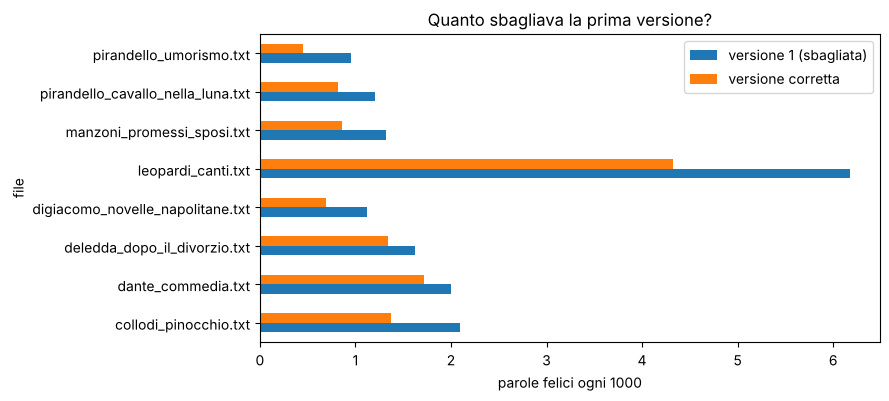

In [8]:
confronto = rapporto_v1(DATI / "testi").set_index("file")["felici_1000"].rename("versione 1 (sbagliata)").to_frame()
confronto["versione corretta"] = tabella.set_index("file")["felici_1000"]
confronto.plot(kind="barh", figsize=(8, 4))
plt.xlabel("parole felici ogni 1000"); plt.title("Quanto sbagliava la prima versione?"); plt.show()

L'errore non era piccolo: per alcune opere la versione 1 **sovrastima** di molto la felicità.
Morale: **chiedete codice, ma chiedete anche i test**, e scrivetene voi su esempi di cui conoscete la risposta.

## 4. K-means: trovare gruppi senza etichette
Nella lezione scorsa abbiamo visto i brani dei cinque autori come una nuvola di punti. Il **k-means** prova a dividerla in
**k gruppi** da solo:

1. sceglie a caso *k* punti come **centri** iniziali;
2. assegna ogni testo al centro più vicino;
3. sposta ogni centro nella media dei suoi testi;
4. ripete 2–3 finché i gruppi non cambiano più.

Il numero *k* lo decidiamo **noi**: l'algoritmo non sa quanti gruppi "esistono".

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

passaggi = pd.read_csv(DATI / "passaggi_autori.csv")
vett = TfidfVectorizer(max_features=3000, min_df=3, stop_words=STOPWORDS)   # togliamo le parole funzionali
X = vett.fit_transform(passaggi["testo"])

km = KMeans(n_clusters=5, n_init=10, random_state=0)
passaggi["cluster"] = km.fit_predict(X)
passaggi["cluster"].value_counts().sort_index()

cluster
0     32
1     98
2    118
3    126
4    226
Name: count, dtype: int64

### Che cosa c'è in ogni gruppo?
Per interpretare un cluster guardiamo le **parole più importanti del suo centro** e, solo dopo, confrontiamo con gli autori
(che l'algoritmo non ha mai visto).

In [10]:
vocab = vett.get_feature_names_out()
for c, centro in enumerate(km.cluster_centers_):
    print(f"cluster {c}:", ", ".join(vocab[np.argsort(centro)[-12:][::-1]]))

cluster 0: mimma, donna, palermo, anni, diploma, lettiga, realtà, ora, può, scialle, sa, morti
cluster 1: giovanna, zia, costantino, giacobbe, brontu, ah, disse, bachisia, isidoro, dejas, zio, voce
cluster 2: pinocchio, burattino, disse, geppetto, fata, babbo, ragazzi, povero, subito, due, invece, pesce
cluster 3: renzo, lucia, don, parte, senza, padre, disse, cosa, fosse, que, uomo, ora
cluster 4: occhi, due, sotto, ora, mano, via, disse, mani, casa, fece, sole, faccia


In [11]:
pd.crosstab(passaggi["cluster"], passaggi["autore"])

autore,Collodi,Deledda,Di Giacomo,Manzoni,Pirandello
cluster,,,,,
0,0,0,0,0,32
1,0,98,0,0,0
2,118,0,0,0,0
3,1,0,1,118,6
4,1,22,119,2,82


### Quanti gruppi? Il punteggio di silhouette
La **silhouette** misura quanto ogni testo è vicino al suo gruppo e lontano dagli altri (da −1 a 1: più alto = gruppi più netti).
È un aiuto, non un oracolo.

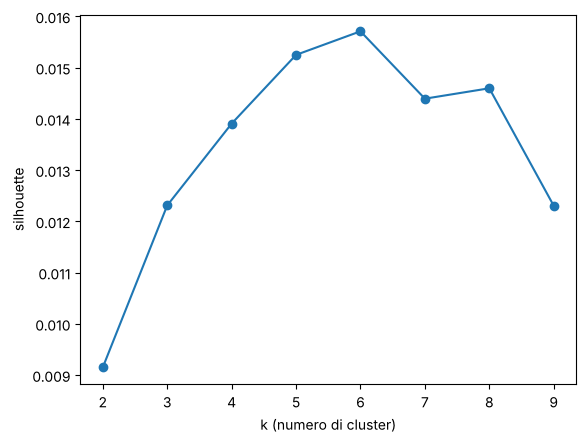

In [12]:
from sklearn.metrics import silhouette_score
ks = range(2, 10)
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)) for k in ks]
plt.plot(list(ks), sil, "o-"); plt.xlabel("k (numero di cluster)"); plt.ylabel("silhouette"); plt.show()

## 5. K-means sulla felicità: quali contesti?
Ora un uso più esplorativo. Prendiamo tutte le frasi del corpus che contengono una parola felice e chiediamo al k-means
di raggrupparle. Non sappiamo che cosa troverà: è proprio questo il punto dell'apprendimento non supervisionato.

In [13]:
def leggi_testo(nome):
    return "\n".join(r for r in (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines() if not r.startswith("#"))

frasi_felici = []
for percorso in sorted((DATI / "testi").glob("*.txt")):
    testo = " ".join(leggi_testo(percorso.name).split())
    for f in re.split(r"(?<=[.!?;])\s+", testo):
        if conta_felici(f) > 0 and len(f.split()) >= 6:
            frasi_felici.append({"opera": percorso.stem, "frase": f})
frasi_felici = pd.DataFrame(frasi_felici)
print(len(frasi_felici), "frasi felici")

vett_f = TfidfVectorizer(min_df=3, stop_words=STOPWORDS + FORME_FELICI)
Xf = vett_f.fit_transform(frasi_felici["frase"])
km_f = KMeans(n_clusters=4, n_init=10, random_state=0)
frasi_felici["cluster"] = km_f.fit_predict(Xf)

vocab_f = vett_f.get_feature_names_out()
for c, centro in enumerate(km_f.cluster_centers_):
    print(f"\ncluster {c} ({(frasi_felici['cluster'] == c).sum()} frasi):", ", ".join(vocab_f[np.argsort(centro)[-10:][::-1]]))
    for f in frasi_felici[frasi_felici["cluster"] == c].sample(2, random_state=0)["frase"]:
        print("   •", f[:160])

630 frasi felici

cluster 0 (461 frasi): ben, vita, esser, gente, due, uomo, tempo, oh, fosse, fuori
   • e Gertrude, per ultimo divertimento, dovette succiarsi le congratulazioni, le lodi, i consigli della vecchia, e sentir parlare di certe sue zie e prozie, le qua
   • Nella sua contentezza egli era semplicemente feroce.

cluster 1 (47 frasi): disse, pinocchio, dopo, ecco, sentì, lucia, po, subito, finalmente, mani
   • Ero contento, ecco, ero contento della mia settimana.
   • Ma credi pure che, in cuor suo, sarà contento anche lui.» Lucia, senza trovar che rispondere a quel ragionamento, non ne sembrava però capacitata: ma Renzo, tut

cluster 2 (76 frasi): ch, son, giorno, esser, ben, mente, onde, ora, vita, foco
   • e son ben contento d'aver visto quella grida.» «Diavolo!» esclamò il dottore, spalancando gli occhi.
   • E a ogni modo, una figlia della quale io son contento, non deve vedersi intorno una persona che le dispiaccia.» Così detto, fece chiamare un'altra donna, e le o



In [14]:
pd.crosstab(frasi_felici["opera"], frasi_felici["cluster"])

cluster,0,1,2,3
opera,,,,
collodi_pinocchio,32,14,1,2
dante_commedia,111,5,35,10
deledda_dopo_il_divorzio,52,9,1,5
digiacomo_novelle_napolitane,31,3,0,0
leopardi_canti,78,2,12,6
manzoni_promessi_sposi,120,11,23,16
pirandello_cavallo_nella_luna,23,2,1,2
pirandello_umorismo,14,1,3,5


Il risultato è tipico del k-means su frasi brevi: un **grande gruppo "tutto il resto"** e alcuni gruppi piccoli che riflettono
più il **registro** (il verso di Dante e Leopardi con *ch', son*; la narrazione con *disse, subito*) che dei "tipi di felicità".
Il k-means raggruppa ciò che si somiglia nelle parole, e le frasi corte condividono poche parole. Dare un nome ai cluster
(o decidere che non ne hanno uno) è un atto **interpretativo**: tocca a noi.

## Riepilogo
- Un buon prompt: **chi siete, contesto, compito, output, vincoli, esempio**.
- Il codice generato va **letto, eseguito e testato** (`assert` su esempi noti).
- **K-means**: *k* centri, assegna, aggiorna, ripeti. Il *k* lo scegliamo noi; la silhouette aiuta ma non decide.
- I cluster non hanno nome: interpretarli è lavoro umanistico.

## Esercizi
Soluzioni in `solutions/05_ai_assistente_kmeans_soluzioni.ipynb`.

**Esercizio 1 — Trova l'errore.** La funzione qui sotto, "scritta da un assistente", dovrebbe restituire le `n` parole più lunghe
di un testo, senza ripetizioni. Scrivete almeno due test con `assert`, trovate l'errore (o gli errori) e correggetelo.
Poi scrivete in una cella di testo il prompt che usereste per chiedere la correzione.

**Esercizio 2 — Estendere l'automazione.** Aggiungete alla funzione `rapporto` una colonna `parola_piu_frequente`
(la parola di contenuto più frequente, senza stopwords: potete usare `data/stopwords_it.txt`) e una colonna `dialogo_100`
(trattini "—" ogni 100 parole). Salvate il CSV e fate un grafico di `dialogo_100`.

**Esercizio 3 — Un altro k.** Ripetete il k-means sui brani d'autore con k = 3 e k = 8. Guardate le tabelle incrociate con gli
autori: che cosa succede agli autori quando i gruppi sono meno di cinque? E quando sono di più? Il k "giusto" esiste?

In [15]:
# Esercizio 1
def parole_piu_lunghe(testo, n=5):
    """Restituisce le n parole più lunghe del testo, senza ripetizioni."""
    parole_testo = testo.split()
    parole_testo.sort(key=len)
    return parole_testo[:n]

parole_piu_lunghe("La felicità, diceva il poeta, è un'attesa: la felicità è sempre domani.", 3)

['è', 'è', 'La']

In [16]:
# Esercizio 2

In [17]:
# Esercizio 3